In [1]:
import keras
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D,Dense, Flatten
from keras.utils import to_categorical
from keras.datasets import mnist
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
     

I0000 00:00:1793421316.577831    9983 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793421316.582440    9983 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793421316.979136    9983 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
I0000 00:00:1793421318.164253    9983 port.cc:153]

In [2]:
(xtrain,ytrain),(xtest,ytest)=mnist.load_data()

In [3]:
xtrain=xtrain.reshape((xtrain.shape[0],28,28,1))
xtest=xtest.reshape((xtest.shape[0],28,28,1))
     

In [4]:
train_norm = xtrain.astype('float32')
test_norm = xtest.astype('float32')
xtrain = train_norm/255.0
xtest = test_norm/255.0
     

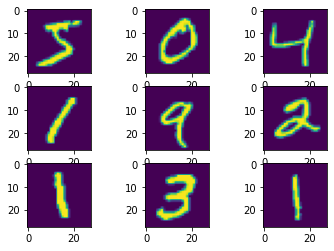

In [5]:
for i in range(9):
  plt.subplot(330+1+i)
  plt.imshow(xtrain[i])

In [8]:
model = Sequential()
model.add(Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)))
model.add(MaxPooling2D(2,2))
model.add(Flatten())
model.add(Dense(100,activation='relu'))
model.add(Dense(10,activation='softmax'))

In [9]:
model.compile(optimizer='sgd',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [10]:
history=model.fit(xtrain,ytrain,epochs=5,validation_data=(xtest,ytest))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8744 - loss: 0.4661 - val_accuracy: 0.9285 - val_loss: 0.2453
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9334 - loss: 0.2232 - val_accuracy: 0.9480 - val_loss: 0.1783
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9490 - loss: 0.1699 - val_accuracy: 0.9559 - val_loss: 0.1552
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9585 - loss: 0.1394 - val_accuracy: 0.9625 - val_loss: 0.1223
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9635 - loss: 0.1206 - val_accuracy: 0.9663 - val_loss: 0.1088


In [11]:
predictions =model.predict(xtest)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


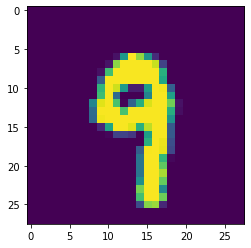

In [12]:
import random
index = random.randint(1,10000)
plt.imshow(xtest[index])

In [13]:
pred_num = max(predictions[index])
for i in range(len(predictions[index])):
    if(predictions[index][i] == pred_num):
        print("Predicted number is: ",i)
        break
     

Predicted number is:  9


In [14]:
print(model.evaluate(xtest,ytest))
     

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9663 - loss: 0.1088
[0.10882052034139633, 0.9663000106811523]


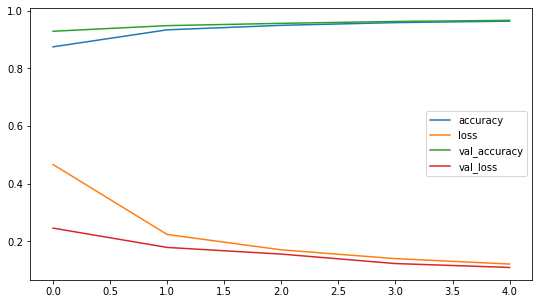

In [15]:
import pandas as pd
pd.DataFrame(history.history).plot(figsize=(9,5))
plt.show()

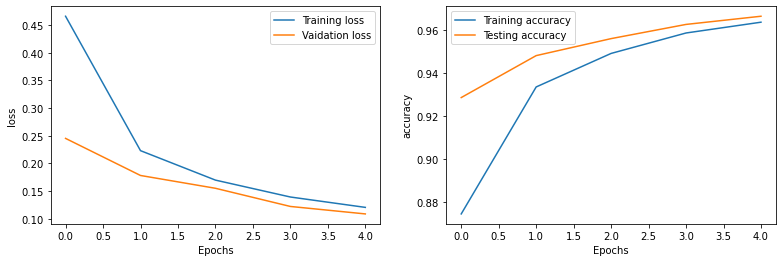

In [16]:
plt.figure(figsize=(13,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='Vaidation loss')
plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Testing accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()